# Evaluation 1 – Token consumption

How much text each model reads and writes per question. Tokens set the cost of a question.

| column | meaning |
|---|---|
| `tokens_in` | tokens the model reads (prompts) |
| `tokens_out` | tokens the model writes |
| `peer_tokens` | tokens the other agent's model spends answering the KQML message |
| `tokens_total` | `tokens_in + tokens_out + peer_tokens` |

The questions are grouped into the **five scenario categories** of the thesis:

| # | category | scenarios | query types in the test set | questions |
|---|---|---|---|---|
| 1 | Data missingness | 1–8 | DATA_LOOKUP | 18 |
| 2 | Geometry missingness | 9–12 | GEOMETRY_LOOKUP | 12 |
| 3 | Constructive operations | 13–16 | SPATIAL_OPERATION | 17 |
| 4 | Relationships | 17–19 | SPATIAL_ADJACENCY, SPATIAL_DIRECTION, SPATIAL_DISTANCE | 34 |
| 5 | Query delegation | 20 | SPATIAL_RELATIONSHIP_BUFFER (city lists in a zone) | 14 |

The 5 out-of-scope questions (UNRELATED) belong to no category and are left out, so 95 questions remain.

**Data:** 4 models × 95 questions × 2 agents × 5 repetitions = 3 800 asks.

In [40]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)

DATA_DIR = Path("..") / "data"
OUT_DIR = Path("outputs") / "01_tokens"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["gpt-4o-mini", "claude-haiku", "qwen3-8b", "qwen3-8b-lora"]
MODEL_LABEL = {"gpt-4o-mini": "GPT-4o mini", "claude-haiku": "Claude Haiku 5.5",
               "qwen3-8b": "Qwen3-8B", "qwen3-8b-lora": "Qwen3-8B + QLoRA"}
MODEL_COLOR = {"gpt-4o-mini": "#2a78d6", "claude-haiku": "#eb6834",
               "qwen3-8b": "#1baf7a", "qwen3-8b-lora": "#eda100"}

CATEGORIES = ["1 Data missingness", "2 Geometry missingness", "3 Constructive operations",
              "4 Relationships", "5 Query delegation"]
CATEGORY_OF_TYPE = {
    "DATA_LOOKUP": "1 Data missingness",
    "GEOMETRY_LOOKUP": "2 Geometry missingness",
    "SPATIAL_OPERATION": "3 Constructive operations",
    "SPATIAL_ADJACENCY": "4 Relationships",
    "SPATIAL_DIRECTION": "4 Relationships",
    "SPATIAL_DISTANCE": "4 Relationships",
    "SPATIAL_RELATIONSHIP_BUFFER": "5 Query delegation",
}
# the two questions without a query type in the answer key
CATEGORY_OF_QID = {"q-ee68a1a070": "2 Geometry missingness",   # "Give me the point for Hamburg, the city"
                   "q-f21a844357": "5 Query delegation"}       # "Show me cities within 60 km of Hannover?"

files = [f for f in DATA_DIR.glob("evaluation_per_model_runs-*/evaluation_*_runs-*.csv") if "summary" not in f.name]
df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in files], ignore_index=True)
df["category"] = df["expected_category"].map(CATEGORY_OF_TYPE).fillna(df["qid"].map(CATEGORY_OF_QID))
df = df[df["category"].notna()].copy()            # drops the 5 UNRELATED questions
df["model"] = pd.Categorical(df["model"], categories=MODELS, ordered=True)
df["category"] = pd.Categorical(df["category"], categories=CATEGORIES, ordered=True)

print(f"{len(df)} asks, {df['qid'].nunique()} questions")
print(df.groupby("category", observed=True)["qid"].nunique().rename("questions").to_frame())

3800 asks, 95 questions
                           questions
category                            
1 Data missingness                18
2 Geometry missingness            12
3 Constructive operations         17
4 Relationships                   34
5 Query delegation                14


## 1. Tokens per question, by model

Mean over all asks of a model (95 questions × 2 agents × 5 repetitions = 950 asks per model).

In [41]:
TOKEN_COLS = ["tokens_in", "tokens_out", "peer_tokens", "tokens_total"]
g = df.groupby("model", observed=True)
by_model = g[TOKEN_COLS].mean()
by_model["peer share %"] = by_model["peer_tokens"] / by_model["tokens_total"] * 100
by_model["asks"] = g.size()
by_model["tokens_total_all_asks"] = g["tokens_total"].sum()
print("mean tokens per question, and the total over all asks of each model:")
by_model.rename(index=MODEL_LABEL).round(1)

mean tokens per question, and the total over all asks of each model:


,tokens_in,tokens_out,peer_tokens,tokens_total,peer share %,asks,tokens_total_all_asks
model,,,,,,,
GPT-4o mini,5223.8,224.2,896.9,6344.9,14.1,950,6027658
Claude Haiku 5.5,8215.4,427.0,1450.9,10093.3,14.4,950,9588625
Qwen3-8B,5069.1,208.1,794.4,6071.6,13.1,950,5768000
Qwen3-8B + QLoRA,5088.0,199.9,814.9,6102.8,13.4,950,5797670


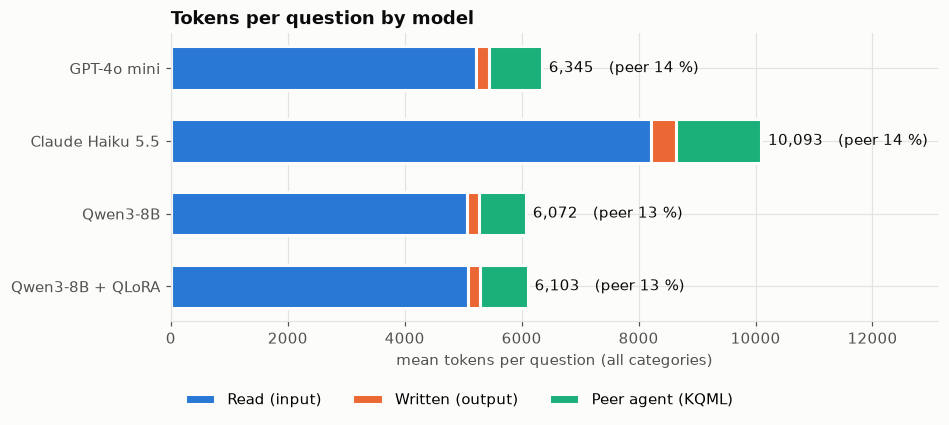

In [42]:
PARTS = [("tokens_in", "Read (input)", "#2a78d6"), ("tokens_out", "Written (output)", "#eb6834"),
         ("peer_tokens", "Peer agent (KQML)", "#1baf7a")]
fig, ax = plt.subplots(figsize=(9, 3.4), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
y = np.arange(len(MODELS))[::-1]
left = np.zeros(len(MODELS))
for col, label, color in PARTS:
    ax.barh(y, by_model.loc[MODELS, col], left=left, height=0.6, color=color, label=label,
            edgecolor="#fcfcfb", linewidth=2)
    left += by_model.loc[MODELS, col].values
for yi, m in zip(y, MODELS):
    ax.text(by_model.loc[m, "tokens_total"] + 120, yi,
            f"{by_model.loc[m, 'tokens_total']:,.0f}   (peer {by_model.loc[m, 'peer share %']:.0f} %)",
            va="center", color="#0b0b0b")
ax.set_yticks(y, [MODEL_LABEL[m] for m in MODELS])
ax.set_xlim(0, left.max() * 1.3)
ax.set_xlabel("mean tokens per question (all categories)")
ax.grid(axis="x", color="#e4e3df")
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_title("Tokens per question by model", loc="left", fontweight="bold")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.2), frameon=False)
fig.savefig(OUT_DIR / "tokens_by_model.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Tokens per question, by model and category

Mean `tokens_total` per question.

In [43]:
by_cat = df.pivot_table(index="category", columns="model", values="tokens_total", aggfunc="mean", observed=True)[MODELS]
by_cat.columns = [MODEL_LABEL[m] for m in MODELS]
by_cat.round(0)

,GPT-4o mini,Claude Haiku 5.5,Qwen3-8B,Qwen3-8B + QLoRA
category,,,,
1 Data missingness,4788.0,8042.0,5091.0,5086.0
2 Geometry missingness,3427.0,6262.0,3699.0,3742.0
3 Constructive operations,6608.0,10640.0,6581.0,6579.0
4 Relationships,7431.0,11423.0,6973.0,7051.0
5 Query delegation,7890.0,12120.0,6557.0,6552.0


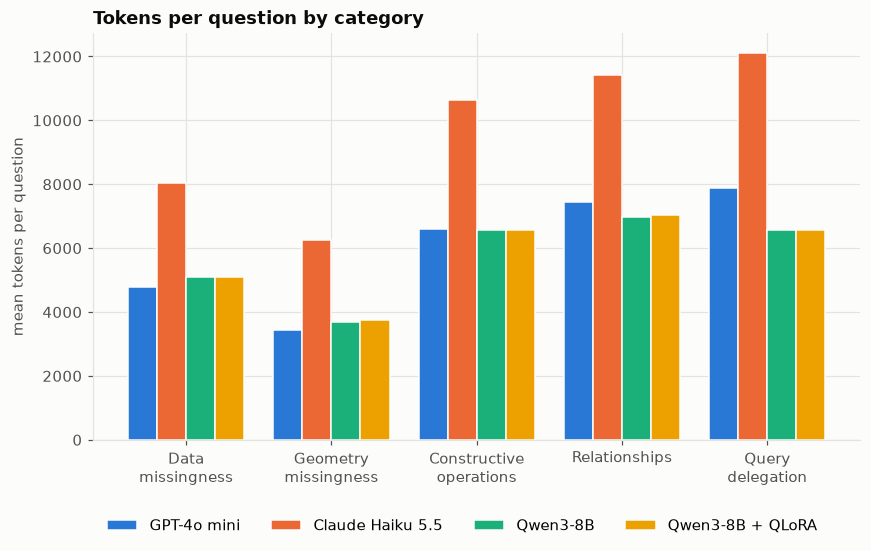

In [44]:
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
n = len(MODELS)
width = 0.8 / n
x = np.arange(len(CATEGORIES))
for i, m in enumerate(MODELS):
    ax.bar(x + (i - (n - 1) / 2) * width, by_cat[MODEL_LABEL[m]], width=width, color=MODEL_COLOR[m],
           label=MODEL_LABEL[m], edgecolor="#fcfcfb", linewidth=1)
ax.set_xticks(x, [c.split(" ", 1)[1].replace(" ", "\n", 1) for c in CATEGORIES])
ax.set_ylabel("mean tokens per question")
ax.grid(axis="y", color="#e4e3df")
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_title("Tokens per question by category", loc="left", fontweight="bold")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.16), frameon=False)
fig.savefig(OUT_DIR / "tokens_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. What the tokens are made of, by category

Mean per question over all four models: what the model reads, what it writes, and what the other agent spends
answering the KQML message.

In [45]:
parts = df.groupby("category", observed=True)[["tokens_in", "tokens_out", "peer_tokens", "tokens_total"]].mean()
parts["peer share %"] = parts["peer_tokens"] / parts["tokens_total"] * 100
parts.round(1)

,tokens_in,tokens_out,peer_tokens,tokens_total,peer share %
category,,,,,
1 Data missingness,4612.8,146.4,992.7,5752.0,17.3
2 Geometry missingness,3827.3,131.0,324.4,4282.6,7.6
3 Constructive operations,6311.5,234.9,1056.0,7602.3,13.9
4 Relationships,7127.4,351.6,740.6,8219.6,9.0
5 Query delegation,5845.0,357.2,2077.6,8279.8,25.1


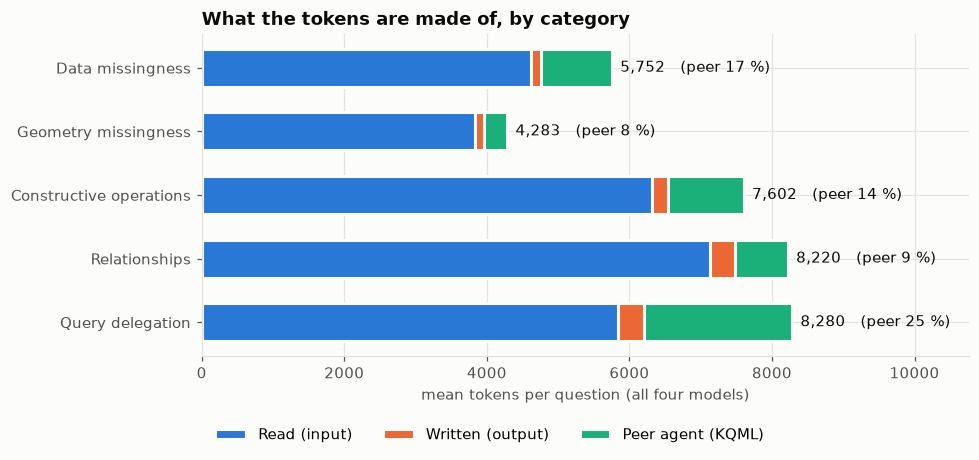

In [46]:
fig, ax = plt.subplots(figsize=(9, 3.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
y = np.arange(len(CATEGORIES))[::-1]
left = np.zeros(len(CATEGORIES))
for col, label, color in PARTS:
    ax.barh(y, parts[col], left=left, height=0.6, color=color, label=label, edgecolor="#fcfcfb", linewidth=2)
    left += parts[col].values
for yi, c in zip(y, CATEGORIES):
    ax.text(parts.loc[c, "tokens_total"] + 120, yi,
            f"{parts.loc[c, 'tokens_total']:,.0f}   (peer {parts.loc[c, 'peer share %']:.0f} %)",
            va="center", color="#0b0b0b")
ax.set_yticks(y, [c.split(" ", 1)[1] for c in CATEGORIES])
ax.set_xlim(0, left.max() * 1.3)
ax.set_xlabel("mean tokens per question (all four models)")
ax.grid(axis="x", color="#e4e3df")
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_title("What the tokens are made of, by category", loc="left", fontweight="bold")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.18), frameon=False)
fig.savefig(OUT_DIR / "tokens_parts_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. What the numbers show

**By model**
* Claude Haiku 5.5 uses the most tokens (about 10 100 per question), roughly 60 % more than the other three
  (about 6 100–6 300). The prompts are the same for all models, so the difference comes mostly from Claude's
  tokenizer counting the same text as more tokens.
* Qwen3-8B and Qwen3-8B + QLoRA use almost the same number of tokens: fine-tuning did not change token use.
* Almost all tokens are input (about 95 %): the prompts with instructions and the database schema. The models
  write very little (200–430 tokens per question).

**By category** – the order is the same for every model:
* **Geometry missingness** is the cheapest (about 4 300 tokens): one lookup, and when a shape is missing the
  peer only has to return it.
* **Data missingness** comes next (about 5 800).
* **Constructive operations, relationships and query delegation** cost the most (about 7 600–8 300): they need
  more SQL steps (e.g. fetch a shape, then compute), and each step is another LLM call with a full prompt.
* **Query delegation** has the largest share of peer tokens (25 %): here the other agent runs the spatial test
  itself, so its model does more of the work. Geometry and relationships have the smallest share (8–9 %),
  because the peer only sends back a shape.
* GPT-4o mini uses more tokens than the Qwen models for relationships and delegation (7 400–7 900 vs
  6 600–7 000) but fewer for data and geometry questions.

In [47]:
with pd.ExcelWriter(OUT_DIR / "tokens.xlsx") as xl:
    by_model.rename(index=MODEL_LABEL).round(1).to_excel(xl, sheet_name="by_model")
    by_cat.round(1).to_excel(xl, sheet_name="by_model_and_category")
    parts.round(1).to_excel(xl, sheet_name="parts_by_category")
print("saved to", OUT_DIR)

saved to outputs\01_tokens
